# BRD4–BD1 | ECFP4–RBF-SVR QSAR model development

**Data snapshot:** 2,816 unique standardized structures, experimental biochemical IC₅₀-derived pIC₅₀. This notebook is fully executable and runs scaffold-disjoint model development, a locked 20% holdout, 20 repeated scaffold validations, 20 y-randomization tests, and applicability-domain inspection. Predictions are computational estimates, not experimental results.

**Leakage control:** locked holdout never participates in hyperparameter optimization, repeated-development validation, or model selection. Repeated scaffold splits are of development molecules only. Mean ± sample SD describes variation across split metrics, not uncertainty of the final holdout estimate.

**Usage:** Run from repository root with `BD1/data/BRD4_BD1_QSAR_model_ready_2816.csv`. Outputs go into `BD1/results/`. Requires `rdkit, numpy, pandas, scipy, scikit-learn, matplotlib, joblib`.

**Performance implementation:** explicitly computed Gaussian RBF Gram matrix on ECFP4 vectors, then fit `SVR(kernel="precomputed")` (mathematically equivalent to RBF-SVR on the same vectors and gamma).

## 1. Read the verified molecular dataset and inspect its integrity

In [1]:
from pathlib import Path
import json, warnings, joblib
import numpy as np, pandas as pd
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.base import clone
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from IPython.display import display
RDLogger.DisableLog('rdApp.*')
ROOT = Path('BD1') if Path('BD1/data/BRD4_BD1_QSAR_model_ready_2816.csv').exists() else Path('/mnt/data')
INPUT = ROOT/'data'/'BRD4_BD1_QSAR_model_ready_2816.csv'
RESULTS = ROOT/'results'; FIGURES=RESULTS/'figures'
FIGURES.mkdir(parents=True,exist_ok=True)
df=pd.read_csv(INPUT)
assert len(df)==2816 and df.standardized_smiles.is_unique and df.pIC50.notna().all()
assert np.isfinite(df.pIC50).all()
print(f'Source: {INPUT} | molecules: {len(df)} | unique SMILES: {df.standardized_smiles.nunique()}')
display(df[['molecule_chembl_ids','pIC50','n_assays','IC50_median_nM']].head())

Source: /mnt/data/data/BRD4_BD1_QSAR_model_ready_2816.csv | molecules: 2816 | unique SMILES: 2816


,molecule_chembl_ids,pIC50,n_assays,IC50_median_nM
0,CHEMBL4647080,6.677781,1,210.0
1,CHEMBL4865857,5.667562,1,2150.0
2,CHEMBL5959369,5.560667,1,2750.0
3,CHEMBL5888347,5.051391,1,8884.0
4,CHEMBL4449965,6.677781,1,210.0


## 2. ECFP4 fingerprints and nonoverlapping Bemis–Murcko scaffolds
Morgan radius 2, 2048 bits. Acyclic molecules receive molecule-specific surrogate scaffold identifiers, preventing unrelated acyclic compounds from all being forced into one group.

In [2]:
mols=[Chem.MolFromSmiles(s) for s in df.standardized_smiles]
assert all(m is not None for m in mols)
gen=rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps=[gen.GetFingerprint(m) for m in mols]
X=np.zeros((len(mols),2048),dtype=np.float32)
for i,f in enumerate(fps): DataStructs.ConvertToNumpyArray(f,X[i])
y=df.pIC50.to_numpy(float)
scaff=np.array([MurckoScaffold.MurckoScaffoldSmiles(mol=m,includeChirality=False) or 'ACYCLIC_'+df.standardized_smiles.iloc[i] for i,m in enumerate(mols)])
print('ECFP4 shape:',X.shape,'Unique scaffolds:',len(set(scaff)))

ECFP4 shape: (2816, 2048) Unique scaffolds: 1317


## 3. Lock independent scaffold-disjoint test set
Reserve approximately 20% of molecules without sharing any scaffold with development. Random seed 2024 is fixed before modeling.

In [3]:
splitter=GroupShuffleSplit(n_splits=1,test_size=0.20,random_state=2024)
idx_dev,idx_test=next(splitter.split(X,y,scaff))
assert set(scaff[idx_dev]).isdisjoint(set(scaff[idx_test]))
assert not set(idx_dev).intersection(idx_test)
print('Development:',len(idx_dev),'| Locked held-out:',len(idx_test),'| shared scaffolds:',len(set(scaff[idx_dev])&set(scaff[idx_test])))
# Precompute squared Euclidean distances; the RBF kernel is exp(-gamma * squared_distance).
# This is exactly RBF-SVR on 2048-bit ECFP4, not a different representation.
from sklearn.metrics.pairwise import euclidean_distances
DIST2=euclidean_distances(X,X,squared=True).astype(np.float32)
np.maximum(DIST2,0,out=DIST2)
GAMMAS=[0.005,0.01]
KERNELS={g:np.exp(-g*DIST2).astype(np.float64) for g in GAMMAS}
print('Computed shared RBF kernel matrices:',GAMMAS)


Development: 2275 | Locked held-out: 541 | shared scaffolds: 0


Computed shared RBF kernel matrices: [0.005, 0.01]


## 4. Optimize RBF-SVR on development data only
GroupKFold(4) and a prespecified finite search of C, gamma, and epsilon. Select by lowest cross-validated RMSE; do not consult held-out outcomes.

In [4]:
from sklearn.model_selection import ParameterGrid
records=[]; gkf=GroupKFold(n_splits=4)
folds=list(gkf.split(idx_dev,y[idx_dev],scaff[idx_dev]))
for gamma in GAMMAS:
    K=KERNELS[gamma]
    for C in [1,10,100]:
        fold_rmse=[]
        for tr,va in folds:
            train=idx_dev[tr];valid=idx_dev[va]
            assert set(scaff[train]).isdisjoint(set(scaff[valid]))
            m=SVR(kernel='precomputed',C=C,epsilon=.1)
            m.fit(K[np.ix_(train,train)],y[train]); pp=m.predict(K[np.ix_(valid,train)])
            fold_rmse.append(np.sqrt(mean_squared_error(y[valid],pp)))
        records.append({'C':C,'gamma':gamma,'epsilon':.1,'CV_RMSE':np.mean(fold_rmse),'CV_RMSE_SD':np.std(fold_rmse,ddof=1)})
cv_results=pd.DataFrame(records).sort_values('CV_RMSE')
cv_results.to_csv(RESULTS/'development_hyperparameter_search.csv',index=False)
best=cv_results.iloc[0]; chosen_gamma=float(best.gamma); chosen_C=float(best.C)
K=KERNELS[chosen_gamma]
model=SVR(kernel='precomputed',C=chosen_C,epsilon=.1)
model.fit(K[np.ix_(idx_dev,idx_dev)],y[idx_dev])
print('Selected gamma:',chosen_gamma,'C:',chosen_C,'| Grouped CV RMSE:',round(float(best.CV_RMSE),4))
display(cv_results)


Selected gamma: 0.01 C: 10.0 | Grouped CV RMSE: 0.5968


,C,gamma,epsilon,CV_RMSE,CV_RMSE_SD
4,10,0.010,0.1,0.596822,0.057663
5,100,0.010,0.1,0.605367,0.046880
1,10,0.005,0.1,0.609349,0.056453
2,100,0.005,0.1,0.631431,0.052238
3,1,0.010,0.1,0.639497,0.076855
0,1,0.005,0.1,0.683540,0.091531


## 5. Evaluate exactly once on the locked held-out scaffolds

In [5]:
def metrics(yt,yp):
    return {'R2':float(r2_score(yt,yp)),'RMSE':float(np.sqrt(mean_squared_error(yt,yp))),'MAE':float(mean_absolute_error(yt,yp)),'Bias':float(np.mean(yp-yt))}
p_test=model.predict(K[np.ix_(idx_test,idx_dev)]);held=metrics(y[idx_test],p_test)
held_df=df.iloc[idx_test].copy(); held_df['observed_pIC50']=y[idx_test];held_df['predicted_pIC50']=p_test
held_df['residual_pIC50']=p_test-y[idx_test];held_df['absolute_error_pIC50']=abs(held_df.residual_pIC50)
held_df['murcko_scaffold']=scaff[idx_test]
held_df.to_csv(RESULTS/'heldout_predictions.csv',index=False)
print('LOCKED held-out, n =',len(idx_test));display(pd.DataFrame([held]))

LOCKED held-out, n = 541


,R2,RMSE,MAE,Bias
0,0.727617,0.592716,0.425493,-0.095476


## 6. Twenty repeated development-only scaffold splits
Use GroupShuffleSplit across the development set with 20 deterministic draws. Keep hyperparameters fixed from Section 4. Report mean ± sample SD and plot all 20 runs.

In [6]:
repeats=[];oof=[]
for run,(tr,va) in enumerate(GroupShuffleSplit(n_splits=20,test_size=.20,random_state=2025).split(X[idx_dev],y[idx_dev],scaff[idx_dev]),1):
    t=idx_dev[tr];v=idx_dev[va]
    assert set(scaff[t]).isdisjoint(set(scaff[v]))
    m=clone(model).fit(K[np.ix_(t,t)],y[t]);p=m.predict(K[np.ix_(v,t)]);mt=metrics(y[v],p)
    repeats.append({'repeat':run,'train_n':len(t),'validation_n':len(v),**mt})
    for j,pred in zip(v,p):oof.append({'repeat':run,'structure_index':int(j),'molecule_chembl_ids':df.molecule_chembl_ids.iloc[j],'observed_pIC50':float(y[j]),'predicted_pIC50':float(pred),'absolute_error_pIC50':float(abs(pred-y[j])),'murcko_scaffold':scaff[j]})
repeats=pd.DataFrame(repeats);oof=pd.DataFrame(oof)
repeats.to_csv(RESULTS/'repeated_scaffold_20x_metrics.csv',index=False)
oof.to_csv(RESULTS/'repeated_scaffold_predictions.csv',index=False)
repeat_summary=pd.DataFrame({'Mean':repeats[['R2','RMSE','MAE','Bias']].mean(),'SD':repeats[['R2','RMSE','MAE','Bias']].std(ddof=1)})
repeat_summary.to_csv(RESULTS/'repeated_metrics_mean_SD.csv')
print('Repeated splits:',len(repeats),'| validation prediction occurrences:',len(oof));display(repeat_summary)

Repeated splits: 20 | validation prediction occurrences: 8606


,Mean,SD
R2,0.703082,0.045331
RMSE,0.598986,0.045155
MAE,0.446208,0.030147
Bias,-0.000883,0.064409


## 7. Y-randomization negative control
Shuffle development pIC₅₀ labels only and refit the fixed selected SVR parameters. Evaluate each permutation on the unchanged held-out features and observed labels, **without** modifying the final model. 20 permutations are a diagnostic, not a formal significance test.

In [7]:
rng=np.random.default_rng(2026);perm=[]
for j in range(20):
    scrambled=rng.permutation(y[idx_dev]);null=clone(model).fit(K[np.ix_(idx_dev,idx_dev)],scrambled)
    mt=metrics(y[idx_test],null.predict(K[np.ix_(idx_test,idx_dev)]));perm.append({'permutation':j+1,**mt})
perm=pd.DataFrame(perm);perm.to_csv(RESULTS/'y_randomization_20x.csv',index=False)
print('True held-out R2:',round(held['R2'],4),'| randomized R2 mean ± SD:',round(perm.R2.mean(),4),'±',round(perm.R2.std(ddof=1),4))

True held-out R2: 0.7276 | randomized R2 mean ± SD: -0.2904 ± 0.1034


## 8. Structural applicability domain and development-derived error relationships
For each OOF prediction, compare the validation compound to its **own split training structures**, never to the locked holdout. The nearest ECFP4 training Tanimoto is a structural screening similarity, not a calibrated error guarantee.

In [8]:
# Compute fold-specific AD scores, using original index mapping of the repeat splits.
from rdkit.DataStructs import BulkTanimotoSimilarity
ad=[]
for run,(tr,va) in enumerate(GroupShuffleSplit(n_splits=20,test_size=.20,random_state=2025).split(X[idx_dev],y[idx_dev],scaff[idx_dev]),1):
    t=idx_dev[tr];v=idx_dev[va]
    for j in v:
        ad.append({'repeat':run,'structure_index':int(j),'nearest_fold_training_tanimoto':max(BulkTanimotoSimilarity(fps[j],[fps[k] for k in t]))})
ad=pd.DataFrame(ad)
oof=oof.merge(ad,on=['repeat','structure_index'],validate='one_to_one')
oof.to_csv(RESULTS/'development_oof_predictions_with_AD.csv',index=False)
ad_rows=[]
for threshold in [.20,.30,.35,.40,.50,.60,.70]:
    v=oof[oof.nearest_fold_training_tanimoto>=threshold]
    ad_rows.append({'cutoff':threshold,'prediction_occurrences':len(v),'coverage':len(v)/len(oof),'MAE':v.absolute_error_pIC50.mean(),'RMSE':np.sqrt(np.mean(v.absolute_error_pIC50**2))})
ad_table=pd.DataFrame(ad_rows);ad_table.to_csv(RESULTS/'AD_threshold_evaluation.csv',index=False)
print('Spearman similarity–absolute-error:',spearmanr(oof.nearest_fold_training_tanimoto,oof.absolute_error_pIC50).statistic)
display(ad_table)

Spearman similarity–absolute-error: -0.22813015050925228


,cutoff,prediction_occurrences,coverage,MAE,RMSE
0,0.20,8600,0.999303,0.445672,0.599296
1,0.30,8493,0.986870,0.441368,0.593491
2,0.35,8378,0.973507,0.434730,0.583761
3,0.40,8232,0.956542,0.427898,0.574157
4,0.50,7628,0.886358,0.412786,0.550115
5,0.60,6429,0.747037,0.387538,0.513600
6,0.70,4115,0.478155,0.364613,0.489894


## 9. Publication figures with uniform approved style
DejaVu Sans; 15-point bold axis labels, 12-point bold ticks, 2-point spines; no title or grid; contrasting colors. Export PNG 600 dpi and vector PDF/SVG. Repeated-split figures show individual runs and Mean ± SD.

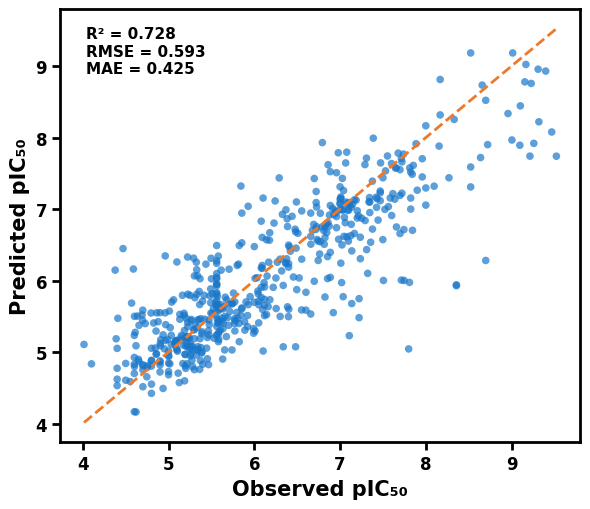

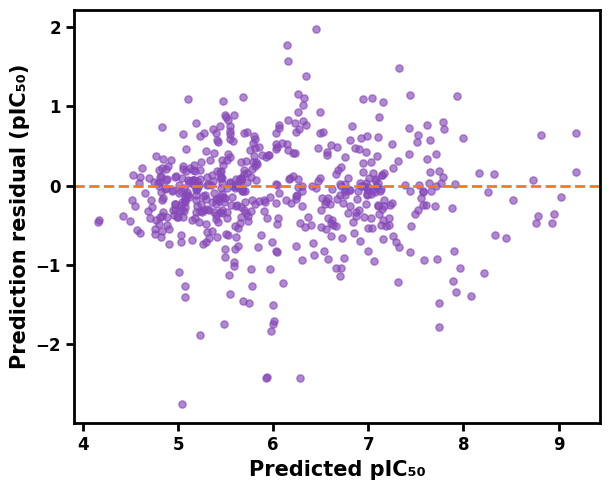

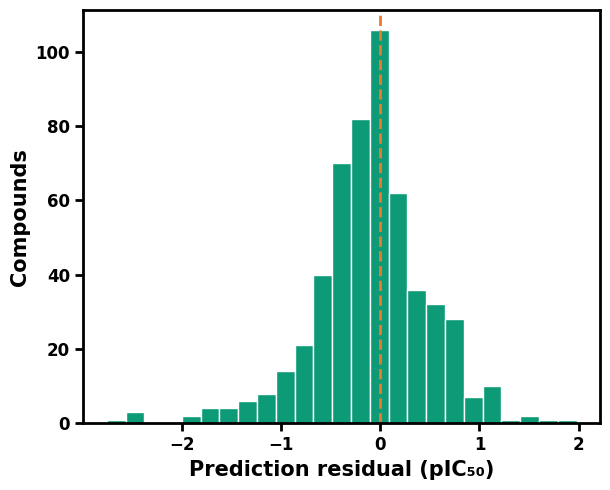

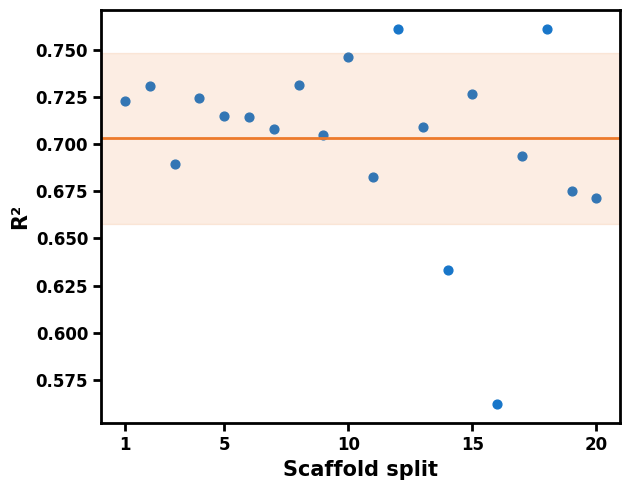

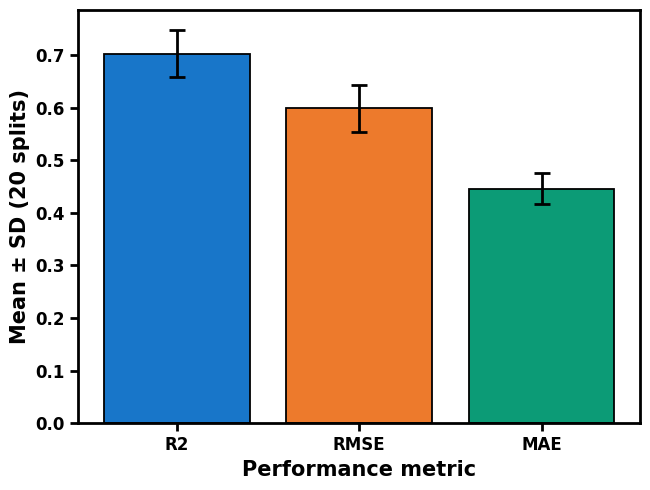

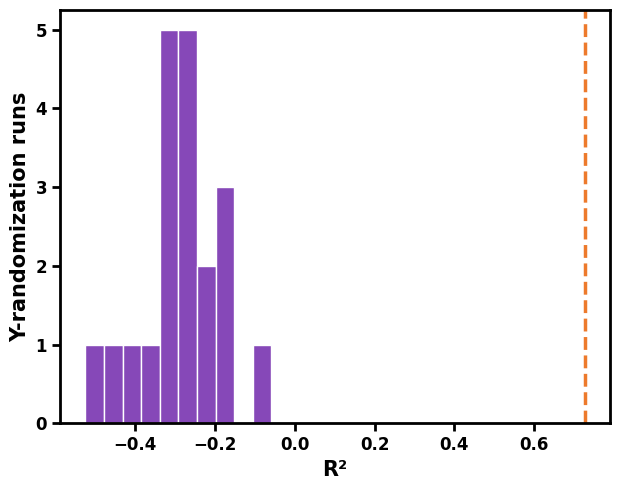

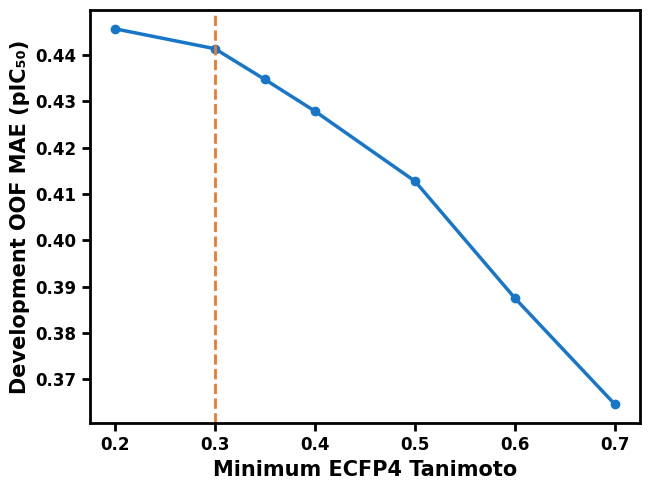

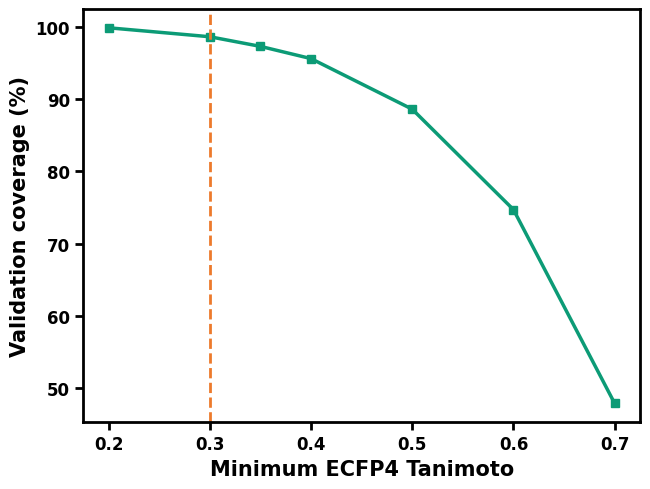

Exported 8 publication figures; each has PNG/PDF/SVG.


In [9]:
plt.rcParams.update({'font.family':'DejaVu Sans','axes.labelsize':15,'axes.labelweight':'bold','xtick.labelsize':12,'ytick.labelsize':12,'axes.linewidth':2,'savefig.dpi':600,'axes.grid':False})
BLUE='#1876C9';ORANGE='#ED7A2C';GREEN='#0C9B76';PURPLE='#8648B8'
def setup(ax,xlabel,ylabel):
    ax.set_xlabel(xlabel,fontweight='bold');ax.set_ylabel(ylabel,fontweight='bold');ax.grid(False)
    for spine in ax.spines.values():spine.set_linewidth(2)
    for tick in ax.get_xticklabels()+ax.get_yticklabels():tick.set_fontweight('bold')
    ax.tick_params(width=2,length=6)
def savefig(fig,name):
    fig.tight_layout()
    for ext in ['png','pdf','svg']:fig.savefig(FIGURES/f'{name}.{ext}',dpi=600,bbox_inches='tight')
    plt.show()
fig,ax=plt.subplots(figsize=(6,5.2));ax.scatter(held_df.observed_pIC50,held_df.predicted_pIC50,s=30,color=BLUE,alpha=.70,edgecolor='none')
lo=min(held_df.observed_pIC50.min(),held_df.predicted_pIC50.min());hi=max(held_df.observed_pIC50.max(),held_df.predicted_pIC50.max())
ax.plot([lo,hi],[lo,hi],color=ORANGE,lw=2,ls='--');setup(ax,'Observed pIC₅₀','Predicted pIC₅₀');ax.text(.05,.96,f"R² = {held['R2']:.3f}\nRMSE = {held['RMSE']:.3f}\nMAE = {held['MAE']:.3f}",transform=ax.transAxes,va='top',fontsize=11,fontweight='bold');savefig(fig,'Figure_01_Heldout_Parity')
fig,ax=plt.subplots(figsize=(6.2,5));ax.scatter(held_df.predicted_pIC50,held_df.residual_pIC50,s=27,color=PURPLE,alpha=.65);ax.axhline(0,lw=2,ls='--',color=ORANGE);setup(ax,'Predicted pIC₅₀','Prediction residual (pIC₅₀)');savefig(fig,'Figure_02_Heldout_Residuals')
fig,ax=plt.subplots(figsize=(6.2,5));ax.hist(held_df.residual_pIC50,bins=25,color=GREEN,edgecolor='white');ax.axvline(0,lw=2,ls='--',color=ORANGE);setup(ax,'Prediction residual (pIC₅₀)','Compounds');savefig(fig,'Figure_03_Residual_Distribution')
fig,ax=plt.subplots(figsize=(6.4,5));ax.scatter(repeats.repeat,repeats.R2,color=BLUE,s=40);ax.axhline(repeats.R2.mean(),color=ORANGE,lw=2);ax.axhspan(repeats.R2.mean()-repeats.R2.std(ddof=1),repeats.R2.mean()+repeats.R2.std(ddof=1),color=ORANGE,alpha=.13);setup(ax,'Scaffold split','R²');ax.set_xticks([1,5,10,15,20]);savefig(fig,'Figure_04_Repeated_Scaffold_R2')
fig,ax=plt.subplots(figsize=(6.6,5));keys=['R2','RMSE','MAE'];means=repeat_summary.loc[keys,'Mean'];sd=repeat_summary.loc[keys,'SD'];ax.bar(keys,means,yerr=sd,capsize=6,color=[BLUE,ORANGE,GREEN],edgecolor='black',linewidth=1.3,error_kw={'elinewidth':2,'capthick':2});setup(ax,'Performance metric','Mean ± SD (20 splits)');savefig(fig,'Figure_05_Repeated_Metrics_Mean_SD')
fig,ax=plt.subplots(figsize=(6.3,5));ax.hist(perm.R2,bins=10,color=PURPLE,edgecolor='white');ax.axvline(held['R2'],color=ORANGE,lw=2.5,ls='--');setup(ax,'R²','Y-randomization runs');savefig(fig,'Figure_06_Y_Randomization')
fig,ax=plt.subplots(figsize=(6.6,5));ax.plot(ad_table.cutoff,ad_table.MAE,color=BLUE,marker='o',lw=2.5);ax.axvline(.30,color=ORANGE,ls='--',lw=2);setup(ax,'Minimum ECFP4 Tanimoto','Development OOF MAE (pIC₅₀)');savefig(fig,'Figure_07_AD_vs_Error')
fig,ax=plt.subplots(figsize=(6.6,5));ax.plot(ad_table.cutoff,100*ad_table.coverage,color=GREEN,marker='s',lw=2.5);ax.axvline(.30,color=ORANGE,ls='--',lw=2);setup(ax,'Minimum ECFP4 Tanimoto','Validation coverage (%)');savefig(fig,'Figure_08_AD_Coverage')
print('Exported',len(list(FIGURES.glob('*.png'))),'publication figures; each has PNG/PDF/SVG.')

## 10. Save model and audited summary
The model is trained only on development compounds. A new model trained on all 2,816 molecules would require its own clearly labeled final refit; it would not replace the locked-test evaluation above.

In [10]:
joblib.dump({'model':model,'training_indices':idx_dev,'test_indices':idx_test,'fingerprint':'ECFP4 radius 2, 2048 bits','development_fingerprints':X[idx_dev],'parameters':{'C':chosen_C,'gamma':chosen_gamma,'epsilon':0.1}},RESULTS/'BD1_RBF_SVR_locked_development.joblib')
summary={'model':'RBF-SVR','representation':'Morgan ECFP4 r2 2048','total_compounds':len(df),'development_n':len(idx_dev),'holdout_n':len(idx_test),'n_scaffolds':len(set(scaff)),'best_parameters':{'C':chosen_C,'gamma':chosen_gamma,'epsilon':0.1},'heldout':held,'repeated_scaffold_mean':repeat_summary['Mean'].to_dict(),'repeated_scaffold_SD':repeat_summary['SD'].to_dict(),'repeated_scaffold_runs':len(repeats),'y_randomization_runs':len(perm),'AD_similarity_threshold_primary_screening':0.30,'AD_note':'Structural inclusion only, not a validated reliability boundary.'}
(RESULTS/'summary.json').write_text(json.dumps(summary,indent=2))
assert len(held_df)==len(idx_test) and len(repeats)==20 and len(perm)==20
print(json.dumps(summary,indent=2))

{
  "model": "RBF-SVR",
  "representation": "Morgan ECFP4 r2 2048",
  "total_compounds": 2816,
  "development_n": 2275,
  "holdout_n": 541,
  "n_scaffolds": 1317,
  "best_parameters": {
    "C": 10.0,
    "gamma": 0.01,
    "epsilon": 0.1
  },
  "heldout": {
    "R2": 0.727616519306722,
    "RMSE": 0.5927155757799388,
    "MAE": 0.4254927288641413,
    "Bias": -0.09547600735116105
  },
  "repeated_scaffold_mean": {
    "R2": 0.7030822291948137,
    "RMSE": 0.5989863050758607,
    "MAE": 0.44620772297515493,
    "Bias": -0.0008826933720122495
  },
  "repeated_scaffold_SD": {
    "R2": 0.045331124863958454,
    "RMSE": 0.045155169880931725,
    "MAE": 0.030146575105438233,
    "Bias": 0.06440860003746837
  },
  "repeated_scaffold_runs": 20,
  "y_randomization_runs": 20,
  "AD_similarity_threshold_primary_screening": 0.3,
  "AD_note": "Structural inclusion only, not a validated reliability boundary."
}
